# Korxona xodimlari HR tahlili

**Muallif:** Xusniddin Yergashov | **Maqsad:** Junior Data Analyst

**Loyiha haqida:** 22 000 xodimdan iborat korxona ma'lumotini API orqali yuklab, pandas yordamida tozaladim va tahlil qildim.

**Asosiy savollar:**
1. Qaysi bo'limlarda maosh eng yuqori?
2. Ma'lumot darajasi va staj maoshga qanchalik ta'sir qiladi?
3. KPI ball bonus bilan bog'liqmi?
4. Ayol va erkak xodimlar maoshida farq bormi?

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

url = "https://dataapi-nch9.onrender.com/korxona"
data = requests.get(url, timeout=60).json()
df = pd.DataFrame(data)
print(df.shape)
df.head()

(22000, 15)


,xodim_id,fio,jins,yosh,viloyat,filial,bolim,lavozim,malumoti,ishga_kirgan_sana,staj_yil,oylik,bonus,kpi_ball,ish_holati
0,10001,Abdullayeva Dilnoza,Ayol,48,Buxoro,Buxoro filiali,Moliya,Mutaxassis,Bakalavr,2009-12-02,16.1,11450000,1140000,83.1,Faol
1,10002,Qodirov Lochin,Erkak,29,Andijon,Andijon filiali,Logistika,Mutaxassis,O'rta maxsus,2024-02-08,1.9,5200000,520000,82.7,Faol
2,10003,Rahimova Zuhra,Ayol,28,Toshkent shahri,Bosh ofis,Savdo,Mutaxassis,Bakalavr,2023-06-27,2.5,7190000,720000,79.0,Faol
3,10004,Qosimov Sardor,Erkak,41,Buxoro,Buxoro filiali,Logistika,Bosh mutaxassis,Bakalavr,2015-03-09,10.8,11310000,570000,67.2,Faol
4,10005,Mirzayev Shohruh,Erkak,40,Toshkent shahri,Toshkent filiali,Logistika,Mutaxassis,O'rta maxsus,2020-01-26,5.9,7020000,350000,65.6,Ta'tilda


## 1. Ma'lumotni tekshirish va tozalash

In [2]:
df.info()
print("\nBo'sh qiymatlar:\n", df.isna().sum())
print("\nTakroriy xodim_id:", df['xodim_id'].duplicated().sum())
print("\nIsh holati turlari:\n", df['ish_holati'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   xodim_id           22000 non-null  int64  
 1   fio                22000 non-null  object 
 2   jins               22000 non-null  object 
 3   yosh               22000 non-null  int64  
 4   viloyat            22000 non-null  object 
 5   filial             22000 non-null  object 
 6   bolim              22000 non-null  object 
 7   lavozim            22000 non-null  object 
 8   malumoti           22000 non-null  object 
 9   ishga_kirgan_sana  22000 non-null  object 
 10  staj_yil           22000 non-null  float64
 11  oylik              22000 non-null  int64  
 12  bonus              22000 non-null  int64  
 13  kpi_ball           22000 non-null  float64
 14  ish_holati         22000 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 2.5+ MB

Bo'sh qiymat

In [3]:
# Sana ustunini datetime ga o'tkazish
df['ishga_kirgan_sana'] = pd.to_datetime(df['ishga_kirgan_sana'])

# Jami daromad (oylik + bonus)
df['jami_daromad'] = df['oylik'] + df['bonus']

# Yosh guruhlari
df['yosh_guruh'] = pd.cut(df['yosh'], bins=[17, 25, 35, 45, 55, 100],
                          labels=['18-25', '26-35', '36-45', '46-55', '56+'])
df.describe()

,xodim_id,yosh,ishga_kirgan_sana,staj_yil,oylik,bonus,kpi_ball,jami_daromad
count,22000.000000,22000.000000,22000,22000.000000,2.200000e+04,2.200000e+04,22000.000000,2.200000e+04
mean,21000.500000,41.592455,2017-12-07 00:24:52.363636480,8.065677,1.121323e+07,1.016361e+06,77.965709,1.222959e+07
min,10001.000000,22.000000,2006-01-07 00:00:00,0.000000,4.510000e+06,0.000000e+00,43.300000,4.740000e+06
25%,15500.750000,35.000000,2015-02-21 00:00:00,4.900000,6.990000e+06,5.200000e+05,71.300000,7.630000e+06
50%,21000.500000,41.000000,2018-07-06 00:00:00,7.500000,9.060000e+06,7.700000e+05,78.000000,9.850000e+06
75%,26500.250000,47.000000,2021-02-09 00:00:00,10.900000,1.266000e+07,1.250000e+06,84.700000,1.381000e+07
max,32000.000000,62.000000,2025-12-28 00:00:00,20.000000,7.234000e+07,1.447000e+07,100.000000,8.681000e+07
std,6350.997297,8.115691,NaN,4.230610,6.820219e+06,8.764083e+05,9.784846,7.462159e+06


## 2. Umumiy ko'rsatkichlar

In [4]:
print(f"Jami xodimlar: {len(df):,}")
print(f"Jami oylik fondi: {df['oylik'].sum():,.0f} so'm")
print(f"O'rtacha oylik: {df['oylik'].mean():,.0f} so'm")
print(f"Median oylik: {df['oylik'].median():,.0f} so'm")
print(f"Eng yuqori / eng past: {df['oylik'].max():,.0f} / {df['oylik'].min():,.0f} so'm")
print(f"Jami bonus: {df['bonus'].sum():,.0f} so'm")
print()
print(df['jins'].value_counts())
print()
print(df['ish_holati'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')

Jami xodimlar: 22,000
Jami oylik fondi: 246,691,070,000 so'm
O'rtacha oylik: 11,213,230 so'm
Median oylik: 9,060,000 so'm
Eng yuqori / eng past: 72,340,000 / 4,510,000 so'm
Jami bonus: 22,359,940,000 so'm

jins
Erkak    14606
Ayol      7394
Name: count, dtype: int64

ish_holati
Faol                95.0%
Ta'tilda             4.0%
Dekret ta'tilida     0.8%
Sinov muddatida      0.2%
Name: proportion, dtype: object


## 3. Bo'limlar bo'yicha tahlil

,xodimlar,ortacha_oylik,ortacha_kpi
bolim,,,
Mijozlarga xizmat,896,8555948.7,77.6
Logistika,2905,8892994.8,78.1
Ishlab chiqarish,5242,9367420.8,78.0
Savdo,5720,9941877.6,77.9
Ma'muriyat,1109,10552146.1,77.9
HR,1104,12165434.8,77.8
Marketing,1349,13406486.3,78.5
Moliya,1492,15535241.3,77.8
Yuridik,630,15945793.7,77.9


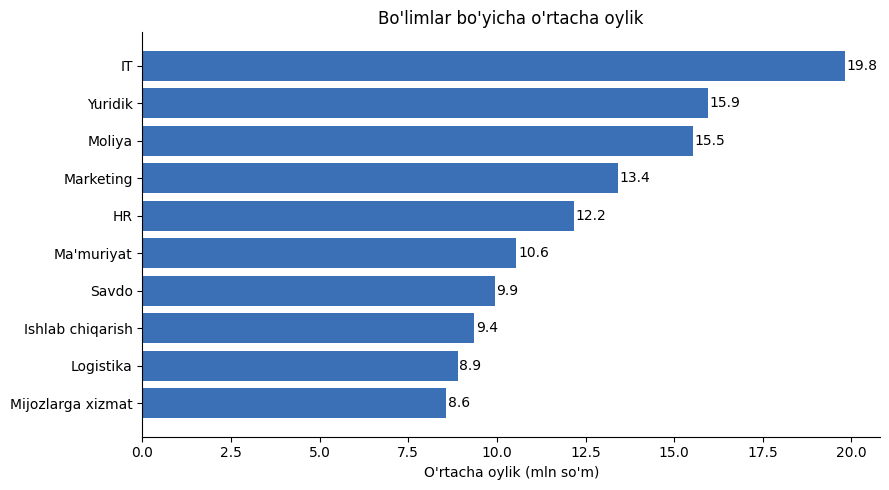

In [5]:
bolim = df.groupby('bolim').agg(
    xodimlar=('xodim_id', 'count'),
    ortacha_oylik=('oylik', 'mean'),
    ortacha_kpi=('kpi_ball', 'mean')
).sort_values('ortacha_oylik').round(1)
display(bolim)

fig, ax = plt.subplots()
ax.barh(bolim.index, bolim['ortacha_oylik'] / 1e6, color='#3b6fb6')
ax.set_xlabel("O'rtacha oylik (mln so'm)")
ax.set_title("Bo'limlar bo'yicha o'rtacha oylik")
for i, v in enumerate(bolim['ortacha_oylik'] / 1e6):
    ax.text(v + 0.05, i, f"{v:.1f}", va='center')
plt.tight_layout()
plt.savefig('grafik_bolim.png', dpi=150)
plt.show()

## 4. Ma'lumot darajasi va staj maoshga ta'siri

malumoti
O'rta maxsus     8273204.0
Bakalavr        11751209.0
Magistr         15590293.0
PhD             27068474.0
Name: oylik, dtype: float64


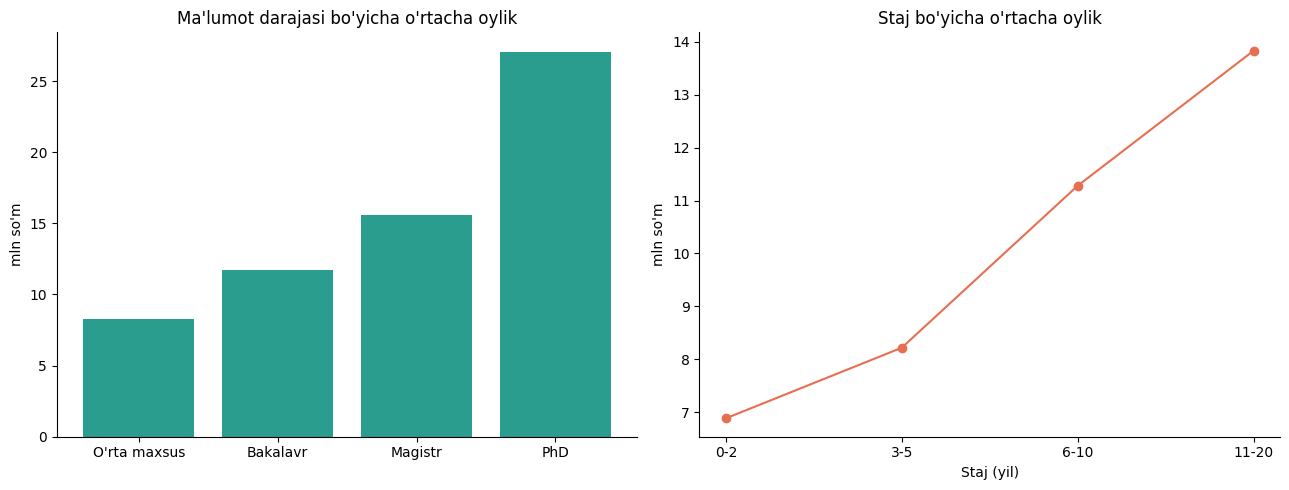

Staj va oylik korrelyatsiyasi: 0.27


In [6]:
tartib = ['O\'rta', 'Bakalavr', 'Magistr', 'PhD']
mal = df.groupby('malumoti')['oylik'].mean().sort_values()
print(mal.round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(mal.index, mal.values / 1e6, color='#2a9d8f')
axes[0].set_title("Ma'lumot darajasi bo'yicha o'rtacha oylik")
axes[0].set_ylabel("mln so'm")

df['staj_guruh'] = pd.cut(df['staj_yil'], bins=[-1, 2, 5, 10, 20, 60],
                          labels=['0-2', '3-5', '6-10', '11-20', '20+'])
st = df.groupby('staj_guruh', observed=True)['oylik'].mean()
axes[1].plot(st.index.astype(str), st.values / 1e6, marker='o', color='#e76f51')
axes[1].set_title("Staj bo'yicha o'rtacha oylik")
axes[1].set_xlabel("Staj (yil)")
axes[1].set_ylabel("mln so'm")

plt.tight_layout()
plt.savefig('grafik_malumot_staj.png', dpi=150)
plt.show()

print("Staj va oylik korrelyatsiyasi:", round(df['staj_yil'].corr(df['oylik']), 2))

## 5. KPI va bonus

KPI va bonus korrelyatsiyasi: 0.54
KPI va oylik korrelyatsiyasi: -0.01

KPI >= 90 bo'lgan xodimlar: 2,514 (11.4%)
Ularning jami bonusi: 5,623,400,000 so'm


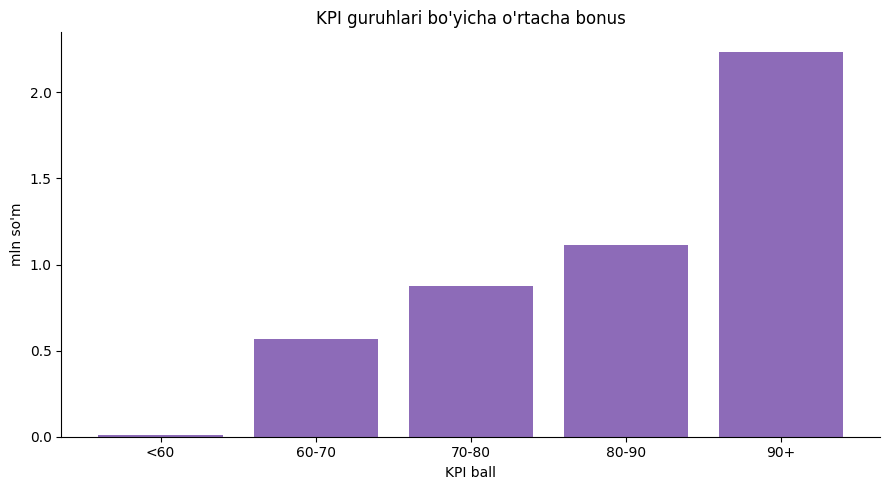

In [7]:
print("KPI va bonus korrelyatsiyasi:", round(df['kpi_ball'].corr(df['bonus']), 2))
print("KPI va oylik korrelyatsiyasi:", round(df['kpi_ball'].corr(df['oylik']), 2))

yuqori = df[df['kpi_ball'] >= 90]
print(f"\nKPI >= 90 bo'lgan xodimlar: {len(yuqori):,} ({len(yuqori)/len(df)*100:.1f}%)")
print(f"Ularning jami bonusi: {yuqori['bonus'].sum():,.0f} so'm")

df['kpi_guruh'] = pd.cut(df['kpi_ball'], bins=[0, 60, 70, 80, 90, 100],
                         labels=['<60', '60-70', '70-80', '80-90', '90+'])
kb = df.groupby('kpi_guruh', observed=True)['bonus'].mean()

fig, ax = plt.subplots()
ax.bar(kb.index.astype(str), kb.values / 1e6, color='#8d6bb8')
ax.set_title("KPI guruhlari bo'yicha o'rtacha bonus")
ax.set_xlabel("KPI ball")
ax.set_ylabel("mln so'm")
plt.tight_layout()
plt.savefig('grafik_kpi_bonus.png', dpi=150)
plt.show()

## 6. Jins bo'yicha maosh

,count,mean,median
jins,,,
Ayol,7394,11571335.0,9520000.0
Erkak,14606,11031947.0,8775000.0


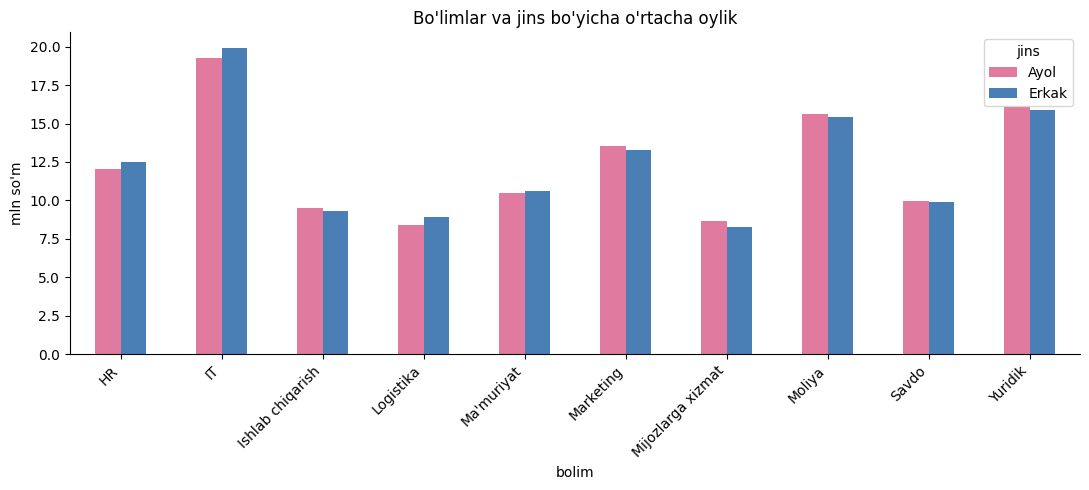

In [8]:
jins = df.groupby('jins')['oylik'].agg(['count', 'mean', 'median']).round(0)
display(jins)

pivot = df.pivot_table(index='bolim', columns='jins', values='oylik', aggfunc='mean') / 1e6
pivot.plot(kind='bar', figsize=(11, 5), color=['#e07a9f', '#4a7fb5'])
plt.title("Bo'limlar va jins bo'yicha o'rtacha oylik")
plt.ylabel("mln so'm")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('grafik_jins.png', dpi=150)
plt.show()

## 7. Viloyatlar bo'yicha taqsimot

In [9]:
vil = df.groupby('viloyat').agg(xodimlar=('xodim_id', 'count'),
                                ortacha_oylik=('oylik', 'mean')).sort_values('xodimlar', ascending=False).round(0)
display(vil)

,xodimlar,ortacha_oylik
viloyat,,
Toshkent shahri,8726,12178995.0
Samarqand,2539,10614210.0
Farg'ona,2128,10692763.0
Andijon,2006,10405813.0
Namangan,1695,10580920.0
Buxoro,1541,10581097.0
Qashqadaryo,1230,10523203.0
Navoiy,1076,10678030.0
Xorazm,1059,10544089.0


## Power BI uchun tayyor ma'lumot
Tozalangan jadvalni CSV qilib saqlaymiz. Power BI dashboardi shu fayldan quriladi.

In [10]:
export = df.drop(columns=['yosh_guruh', 'staj_guruh', 'kpi_guruh'], errors='ignore')
export.to_csv('xodimlar_tozalangan.csv', index=False, encoding='utf-8-sig')
print(export.shape, "-> xodimlar_tozalangan.csv saqlandi")

(22000, 16) -> xodimlar_tozalangan.csv saqlandi


## 8. Asosiy xulosalar

> Kodni ishga tushirgach, yuqoridagi natijalarga qarab shu bo'limni o'z so'zlaringiz bilan to'ldiring.

1. **Bo'limlar:** eng yuqori maosh ... bo'limida (... mln so'm), eng past ... bo'limida.
2. **Ma'lumot va staj:** ... (korrelyatsiya ...).
3. **KPI va bonus:** ...
4. **Jins:** ayol va erkak o'rtasidagi o'rtacha maosh farqi ...
5. **Tavsiya:** ...

## Foydalanilgan vositalar
Python, pandas, NumPy, matplotlib, requests